In [ ]:
import io
import sys
import zipfile
from glob import glob
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import xarray as xr
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.io.shapereader as shpreader
from matplotlib.collections import LineCollection
from pyproj import Transformer

sys.path.append("../..")
from src.data import dataset_utils as du
from src.data import graph_utils as gu

ZARR_PATH = "/work/ka1176/shared_data/2025-wwm-emulator-schism/processed_RUN04b_JUWELS_wpile.zarr"
BOUNDARY_NODES_CSV = "../../src/data/node_selection/boundary_nodes.csv"
DATA_CRS = ccrs.UTM(32)  # SCHISM_hgrid_node_x/y are projected UTM zone 32N
LONLAT_TRANSFORMER = Transformer.from_crs("epsg:32632", "epsg:4326", always_xy=True)

ds_true = xr.open_dataset(ZARR_PATH, engine="zarr", chunks="auto")

node_x = ds_true["SCHISM_hgrid_node_x"].values
node_y = ds_true["SCHISM_hgrid_node_y"].values

print(f"node_x range: [{node_x.min():.2f}, {node_x.max():.2f}]")
print(f"node_y range: [{node_y.min():.2f}, {node_y.max():.2f}]")
print(f"Total nodes: {len(node_x)}, total time steps: {ds_true.sizes['time']}")

node_x range: [-170936.47, 588878.00]
node_y range: [5550339.00, 6211776.00]
Total nodes: 589428, total time steps: 8760


/tmp/ipykernel_251617/3658512320.py:28: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 20. This could degrade performance. Instead, consider rechunking after loading.
  ds_true = xr.open_dataset(ZARR_PATH, engine="zarr", chunks="auto")
/tmp/ipykernel_251617/3658512320.py:28: UserWarning: The specified chunks separate the stored chunks along dimension "nSCHISM_hgrid_edge" starting at index 1677719. This could degrade performance. Instead, consider rechunking after loading.
  ds_true = xr.open_dataset(ZARR_PATH, engine="zarr", chunks="auto")
/tmp/ipykernel_251617/3658512320.py:28: UserWarning: The specified chunks separate the stored chunks along dimension "two" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  ds_true = xr.open_dataset(ZARR_PATH, engine="zarr", chunks="auto")
/tmp/ipykernel_251617/3658512320.py:28: UserWarning: The specified chunks separate the stored chunks along dim

In [ ]:
PAPER_WIDE = (7.1, 3.5)
PAPER_NARROW = (3.5, 3.5/1.6)

In [ ]:
import seaborn as sns
sns.set_context("paper")

## Study domain

/tmp/ipykernel_251617/2384704258.py:71: DeprecationWarning: The 'shapely.vectorized.contains' function is deprecated and will be removed a future version. Use 'shapely.contains_xy' instead (available since shapely 2.0.0).
  inside_mask = contains(domain_polygon, lon2d, lat2d)
/tmp/ipykernel_251617/2384704258.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


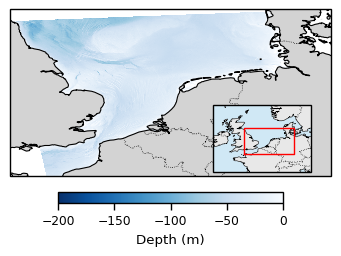

In [ ]:
"""
Fetch GEBCO_2020 bathymetry from NOAA's public ERDDAP server (griddap),
clipped to the study domain, with everything OUTSIDE the actual
(UTM-aligned, hence rotated in lon/lat) domain masked white.

Why ERDDAP/GEBCO instead of EMODnet WCS:
- Plain HTTP GET, no capabilities handshake, no server-side XML fault
  reports to parse, no per-request byte-size cap to negotiate.
- Subsetting happens server-side via bracket-index or lat/lon range
  syntax, so you only download what you need.

Requires: xarray, netCDF4, shapely, numpy, matplotlib, cartopy
    pip install netCDF4 shapely --break-system-packages
"""

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import xarray as xr
from shapely.geometry import Polygon, Point
from shapely.vectorized import contains

# ---------------------------------------------------------------------
# 1) Build the ROTATED domain polygon in lon/lat (not just its bbox)
# ---------------------------------------------------------------------
pad_x = 0.02 * (node_x.max() - node_x.min())
pad_y = 0.02 * (node_y.max() - node_y.min())

xmin, xmax = node_x.min() - pad_x, node_x.max() + pad_x
ymin, ymax = node_y.min() - pad_y, node_y.max() + pad_y

corners_x_utm = [xmin, xmax, xmax, xmin]
corners_y_utm = [ymin, ymin, ymax, ymax]
corner_lons, corner_lats = LONLAT_TRANSFORMER.transform(corners_x_utm, corners_y_utm)
domain_polygon = Polygon(zip(corner_lons, corner_lats))

lon_min, lon_max = min(corner_lons), max(corner_lons)
lat_min, lat_max = min(corner_lats), max(corner_lats)

fetch_pad_lon = 0.02 * (lon_max - lon_min)
fetch_pad_lat = 0.02 * (lat_max - lat_min)
fetch_lon_min, fetch_lon_max = lon_min - fetch_pad_lon, lon_max + fetch_pad_lon
fetch_lat_min, fetch_lat_max = lat_min - fetch_pad_lat, lat_max + fetch_pad_lat

fetch_lon_max = 9.51

# ---------------------------------------------------------------------
# 2) Fetch GEBCO_2020 via ERDDAP griddap -- a plain HTTP GET, xarray
#    opens it directly over OPeNDAP without a manual download step.
# ---------------------------------------------------------------------
ERDDAP_URL = "https://coastwatch.pfeg.noaa.gov/erddap/griddap/GEBCO_2020"

# xarray can open the OPeNDAP endpoint lazily -- only the bbox slice
# below actually gets pulled over the wire.
ds = xr.open_dataset(ERDDAP_URL)  # lazy; needs 'pydap' or netCDF4 w/ opendap support

# GEBCO_2020 on this ERDDAP server exposes lat/lon as coordinate dims
# and an elevation variable (name may be 'elevation' -- check ds.data_vars
# if this KeyErrors).
da = ds["elevation"].sel(
    latitude=slice(fetch_lat_min, fetch_lat_max),
    longitude=slice(fetch_lon_min, fetch_lon_max),
).load()  # .load() triggers the actual (now-small) download

# ---------------------------------------------------------------------
# 3) Mask everything outside the ROTATED domain polygon
# ---------------------------------------------------------------------
lon2d, lat2d = np.meshgrid(da.longitude.values, da.latitude.values)
inside_mask = contains(domain_polygon, lon2d, lat2d)

depth = da.values  # GEBCO convention: negative = below sea level
sea_only = np.where(inside_mask & (depth < 0), depth, np.nan)

# ---------------------------------------------------------------------
# 4) Plot: colored bathymetry inside the domain, WHITE outside it
# ---------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(3.5, 3.5), subplot_kw={"projection": ccrs.PlateCarree()})
ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
ax.set_facecolor("white")

norm = matplotlib.colors.Normalize(vmin=-200, vmax=0)
mesh = ax.pcolormesh(
    da.longitude.values,
    da.latitude.values,
    sea_only,
    transform=ccrs.PlateCarree(),
    cmap="Blues_r",
    norm=norm,
    shading="auto",
    zorder=1,
)

ax.add_feature(cfeature.LAND, facecolor="lightgray", zorder=2)
ax.coastlines(resolution="10m", linewidth=0.8, zorder=3)
ax.add_feature(cfeature.BORDERS, linestyle=":", linewidth=0.5, zorder=3)

dom_lons, dom_lats = domain_polygon.exterior.xy
#ax.plot(
#    list(dom_lons) + [dom_lons[0]],
#    list(dom_lats) + [dom_lats[0]],
#    color="red",
#    linewidth=1.2,
#    transform=ccrs.PlateCarree(),
#    zorder=4,
#)

cbar = fig.colorbar(mesh, ax=ax, orientation="horizontal", shrink=0.7, pad=0.05)
cbar.set_label("Depth (m)")
#ax.set_title("Study domain bathymetry (GEBCO_2020)")


from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# --- inset: manual positioning instead of inset_locator ---
# [left, bottom, width, height] in FIGURE-relative coordinates (0-1)
axins = fig.add_axes([0.62, 0.22, 0.28, 0.28], projection=ccrs.PlateCarree())
axins.set_extent([-10, 15, 45, 62], crs=ccrs.PlateCarree())
axins.add_feature(cfeature.LAND, facecolor="#e8e8e8", zorder=1)
axins.add_feature(cfeature.OCEAN, facecolor="#d0e8f5", zorder=0)
axins.add_feature(cfeature.BORDERS, linestyle=":", linewidth=0.5, zorder=3)
axins.coastlines(resolution="50m", linewidth=0.4, zorder=2)

# red box marking where the main map sits within this broader view
minx, miny, maxx, maxy = domain_polygon.bounds
axins.plot(
    [minx, maxx, maxx, minx, minx],
    [miny, miny, maxy, maxy, miny],
    color="red", linewidth=1.0, transform=ccrs.PlateCarree(), zorder=3,
)
axins.set_xticks([]); axins.set_yticks([])




plt.tight_layout()
plt.savefig("study_domain_bathymetry_gebco.png", dpi=200)
plt.show()

## Data splits

Plot mean sig wave height across the study domain keeping the time axis and highlight data splits as observed in the experiment configuration swh_1h_mlp

In [ ]:
# domain-mean SWH per time step -- triggers a full reduction over ~590k nodes x 8760 steps
swh_domain_mean = ds_true["sigWaveHeight"].mean(dim="nSCHISM_hgrid_node").compute()

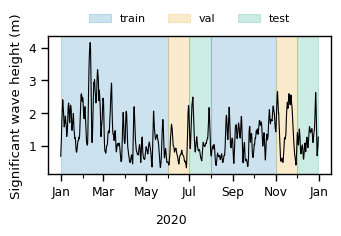

In [ ]:
import matplotlib.dates as mdates

# --- config -----------------------------------------------------------
SPLIT_DAYS = {
    "train": [[1, 152], [214, 305]],
    "val": [[153, 182], [306, 335]],
    "test": [[183, 213], [336, 365]],
}
SPLIT_COLORS = {"train": "#0072B2", "val": "#E69F00", "test": "#009E73"}
SMOOTH_HOURS = 48  # <-- configurable smoothing window, in hours

time_delta = ds_true.time.values[1] - ds_true.time.values[0]
samples_per_day = int(pd.Timedelta(days=1) / time_delta)
samples_per_hour = pd.Timedelta(hours=1) / time_delta



# --- smoothing ----------------------------------------------------------
smooth_window = max(1, round(SMOOTH_HOURS * samples_per_hour))
if smooth_window > 1:
    swh_plot = swh_domain_mean.rolling(time=smooth_window, center=True, min_periods=1).mean()
else:
    swh_plot = swh_domain_mean

fig, ax = plt.subplots(figsize=PAPER_NARROW)
swh_plot.plot(ax=ax, color="k", linewidth=0.8)

for split, ranges in SPLIT_DAYS.items():
    for start_day, end_day in ranges:
        start_idx = (start_day - 1) * samples_per_day
        end_idx = end_day * samples_per_day - 1
        ax.axvspan(
            ds_true.time.values[start_idx],
            ds_true.time.values[end_idx],
            color=SPLIT_COLORS[split],
            alpha=0.2,
            label=split,
        )

# de-duplicate legend labels (axvspan is called once per contiguous range per split)
handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax.legend(
    by_label.values(), by_label.keys(),
    loc="lower center", bbox_to_anchor=(0.5, 1.02),
    ncol=3, frameon=False, fontsize=8,
)

# --- x-axis: tick every month, abbreviated label, no year ---------------
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_minor_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))

#plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

ax.set_xlabel("")
ax.set_ylabel("Significant wave height (m)")

fig.tight_layout()

# year label centered at the very bottom, below the month ticks
fig.text(0.5, 0, "2020", ha="center", va="top", fontsize=9)

plt.savefig("train_val_test_split.png", dpi=180)
plt.show()

## Subgraph partition

In [ ]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
nx = ds_true.SCHISM_hgrid_node_x
ny = ds_true.SCHISM_hgrid_node_y
ed = ds_true.SCHISM_hgrid_edge_nodes.isel(two=0)

In [ ]:
MAX_NODES_PARTITION = 50

# --- Build adjacency and partition the domain, exactly as predict_gcn.py does ---
adjacency = gu.build_adjacency(ds_true)

boundary_node_ids = du.load_node_indices(BOUNDARY_NODES_CSV)
ds_node_ids = ds_true.nSCHISM_hgrid_node.values
id_to_pos = {int(nid): pos for pos, nid in enumerate(ds_node_ids)}
boundary_positions = np.array([id_to_pos[int(nid)] for nid in boundary_node_ids if int(nid) in id_to_pos])
adjacency = gu.remove_boundary_nodes(adjacency, boundary_positions)

partitions = gu.partition_domain_disjoint(n_nodes=len(ds_node_ids), adjacency=adjacency, node_x = nx.values, node_y=ny.values, target_nodes=MAX_NODES_PARTITION)
print(f"{len(partitions)} sub-graphs covering the domain (max_nodes={MAX_NODES_PARTITION})")

10939 sub-graphs covering the domain (max_nodes=50)


In [ ]:
# partition: CENTER NODE; SUBGRAPH NODES; EDGE INDEX; CENTER LOCAL INDEX

In [ ]:
partitions[1000]

(57181,
 array([49515, 49516, 49517, 49518, 50978, 50979, 50980, 50981, 50982,
        50983, 52478, 52479, 52480, 52481, 52482, 52483, 54014, 54015,
        54016, 54017, 54018, 54019, 54020, 55575, 55576, 55577, 55578,
        55579, 55580, 55581, 55582, 57178, 57179, 57180, 57181, 57182,
        57183, 57184, 57185, 58814, 58815, 58816, 58817, 58818, 58819,
        58820, 58821, 58822, 60469, 60470, 60471, 60472, 60473, 60474,
        60475]),
 tensor([[ 0,  0,  0,  0,  1,  1,  1,  1,  1,  2,  2,  2,  2,  2,  3,  3,  3,  3,
           4,  4,  4,  5,  5,  5,  5,  5,  5,  6,  6,  6,  6,  6,  6,  6,  7,  7,
           7,  7,  7,  7,  7,  8,  8,  8,  8,  8,  8,  8,  9,  9,  9,  9,  9, 10,
          10, 10, 10, 10, 10, 11, 11, 11, 11, 11, 11, 11, 12, 12, 12, 12, 12, 12,
          12, 13, 13, 13, 13, 13, 13, 13, 14, 14, 14, 14, 14, 14, 14, 15, 15, 15,
          15, 15, 16, 16, 16, 16, 16, 17, 17, 17, 17, 17, 17, 17, 18, 18, 18, 18,
          18, 18, 18, 19, 19, 19, 19, 19, 19, 19, 20, 20,

In [ ]:
## how large are the partitions

In [ ]:
np.median(all_px)

NameError: name 'all_px' is not defined

In [ ]:
np.median(all_py)

In [ ]:
np.mean(all_px), np.mean(all_py)

In [ ]:
plt.hist(np.log10(all_px + 1e-6));
plt.xlim(0, 5);

In [ ]:
for ip in range(np.argmin(all_px), np.argmin(all_px)+1):
    plt.scatter(nx.sel(nSCHISM_hgrid_node=partitions[ip][1]), ny.sel(nSCHISM_hgrid_node=partitions[ip][1]))
    plt.scatter(nx.sel(nSCHISM_hgrid_node=partitions[ip][0]), ny.sel(nSCHISM_hgrid_node=partitions[ip][0]))


In [ ]:
for ip in range(np.argmax(all_px), np.argmax(all_px)+1):
    plt.scatter(nx.sel(nSCHISM_hgrid_node=partitions[ip][1]), ny.sel(nSCHISM_hgrid_node=partitions[ip][1]))
    plt.scatter(nx.sel(nSCHISM_hgrid_node=partitions[ip][0]), ny.sel(nSCHISM_hgrid_node=partitions[ip][0]))


Selected partitions to plot

In [ ]:
centers = np.array([p[0] for p in partitions])
center_x, center_y = LONLAT_TRANSFORMER.transform(node_x[centers], node_y[centers])

In [ ]:
center_latlon = np.stack([center_x, center_y]).T

In [ ]:
my_points = [(1.741, 53.703), # open sea close to England
             #(3.774, 55.229), # Dogger Bank
             (9.1530, 53.8784), # Brunsbüttel
             (6.6922, 53.60685), # close to Borkum
             (7.9362, 54.3237), # close to Helgoland
            ]

In [ ]:
ips = []

for mp in my_points:
    distance = np.sqrt( (center_x - mp[0])**2 + (center_y - mp[1])**2 )
    print(center_latlon[np.argmin(distance)])

    ips.append(np.argmin(distance))

[ 1.7696345  53.71272744]
[ 9.14248986 53.88244524]
[ 6.72410206 53.63569291]
[ 7.92325567 54.31081835]


Overview where subgraphs are taken from

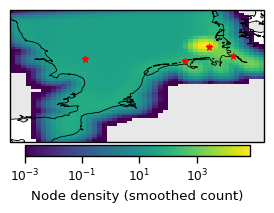

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors
from scipy.ndimage import gaussian_filter
import cartopy.crs as ccrs
import cartopy.feature as cfeature

fig, ax = plt.subplots(1, 1, subplot_kw={"projection": ccrs.PlateCarree()}, figsize=PAPER_NARROW)

ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
ax.set_facecolor("white")

lon_all, lat_all = LONLAT_TRANSFORMER.transform(nx.values, ny.values)

nbins = 50  # coarser: aim for several nodes per cell, not 0-1
density, lon_edges, lat_edges = np.histogram2d(
    lon_all, lat_all, bins=nbins, range=[[lon_min, lon_max], [lat_min, lat_max]]
)

# smooth so it reads as a continuous field instead of blocky counting cells
density_smooth = gaussian_filter(density, sigma=1.0)
density_smooth = np.ma.masked_where(density_smooth <= 0, density_smooth)

mesh = ax.pcolormesh(
    lon_edges, lat_edges, density_smooth.T,
    cmap="viridis",
    norm=matplotlib.colors.LogNorm(vmin=max(density_smooth.min(), 1e-3), vmax=density_smooth.max()),
    transform=ccrs.PlateCarree(),
    zorder=1.5,
)

ax.add_feature(cfeature.LAND, facecolor="#e8e8e8", zorder=1)
ax.coastlines(resolution="10m", linewidth=0.6, zorder=3)

for ip in ips:
    nx_lon, nx_lat = LONLAT_TRANSFORMER.transform(
        nx.sel(nSCHISM_hgrid_node=partitions[ip][0]).values,
        ny.sel(nSCHISM_hgrid_node=partitions[ip][0]).values,
    )
    ax.scatter(nx_lon, nx_lat, color="red", marker="*", zorder=4)

cbar = fig.colorbar(mesh, ax=ax, orientation="horizontal", shrink=0.7, pad=0.02,)
cbar.set_label("Node density (smoothed count)")

fig.tight_layout()
plt.show()

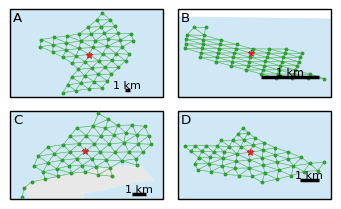

In [ ]:
fig, axs = plt.subplots(2, 2, subplot_kw={"projection": ccrs.PlateCarree()}, figsize=PAPER_NARROW)

axs = axs.flatten()

from pyproj import Geod

def add_scale_bar(ax, length_km=1.0, location=(0.95, 0.05), color="black", linewidth=2.5, fontsize=8):
    """
    Draw a geodesically-accurate scale bar on a lon/lat matplotlib axes.

    ax: matplotlib Axes with data in (lon, lat) -- plain axes or a
        cartopy GeoAxes using PlateCarree (degree-based data coords).
    length_km: length the bar represents, in km.
    location: (x, y) in AXES-relative coords (0-1) for the bar's
        RIGHT/anchor end -- default puts it bottom-right.
    """
    geod = Geod(ellps="WGS84")

    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # anchor point in data (lon/lat) coords, from axes-relative location
    anchor_lon = xlim[0] + location[0] * (xlim[1] - xlim[0])
    anchor_lat = ylim[0] + location[1] * (ylim[1] - ylim[0])

    # walk WEST from the anchor by length_km, at this latitude, to get
    # the bar's other endpoint -- geodesically correct regardless of lat
    start_lon, start_lat, _ = geod.fwd(anchor_lon, anchor_lat, 270, length_km * 1000)

    ax.plot(
        [start_lon, anchor_lon], [anchor_lat, anchor_lat],
        color=color, linewidth=linewidth, solid_capstyle="butt",
        transform=ax.transData, zorder=10, clip_on=False,
    )
    ax.text(
        (start_lon + anchor_lon) / 2, anchor_lat,
        f"{length_km:g} km",
        ha="center", va="bottom", fontsize=fontsize, zorder=10,
    )

for ip, ax, lb in zip(ips, axs, ["A", "B", "C", "D"]):

    # nodes
    cnx_lon, cnx_lat = LONLAT_TRANSFORMER.transform(nx.sel(nSCHISM_hgrid_node=partitions[ip][0]).values, ny.sel(nSCHISM_hgrid_node=partitions[ip][0]).values)
    ax.scatter(cnx_lon, cnx_lat, color="C3", marker="*", zorder=4)

    nx_lon, nx_lat = LONLAT_TRANSFORMER.transform(nx.sel(nSCHISM_hgrid_node=partitions[ip][1]).values, ny.sel(nSCHISM_hgrid_node=partitions[ip][1]).values)
    ax.scatter(nx_lon, nx_lat, s=4, color="C2", zorder=3)


    # edges
    edge_index = partitions[ip][2]

    edge_src = edge_index[0].numpy()
    edge_dst = edge_index[1].numpy()
    mask = edge_src != edge_dst
    segments = np.stack(
        [np.column_stack([nx_lon[edge_src[mask]], nx_lat[edge_src[mask]]]),
            np.column_stack([nx_lon[edge_dst[mask]], nx_lat[edge_dst[mask]]])],
        axis=1,
    )
    ax.add_collection(
        LineCollection(segments, colors=["C2"], linewidths=0.4, alpha=0.5, zorder=2)
    )

    # generic

    ax.add_feature(cfeature.LAND, facecolor="#e8e8e8", zorder=1)
    ax.add_feature(cfeature.OCEAN, facecolor="#d0e8f5", zorder=0)

    

    # label
    ax.text(0.02, 0.98, lb, transform=ax.transAxes, ha="left", va="top")

    ax.set_aspect("equal", adjustable="datalim")
    # extent
    add_scale_bar(ax, length_km=1.0, location=(0.92, 0.08))


fig.tight_layout()

plt.savefig("subgraphs_selected_locations.png", dpi=200)

In [ ]:
for ip in range(999, 1004):
    plt.scatter(nx.sel(nSCHISM_hgrid_node=partitions[ip][1]), ny.sel(nSCHISM_hgrid_node=partitions[ip][1]))
    plt.scatter(nx.sel(nSCHISM_hgrid_node=partitions[ip][0]), ny.sel(nSCHISM_hgrid_node=partitions[ip][0]))


In [ ]:
def plot_partition_zoom(ax, partitions, node_x, node_y, x_range, y_range, cmap_name="tab20"):
    """Scatter + edge plot of the BFS sub-graph partitions overlapping a bounding box, one colour per partition."""
    cmap = plt.get_cmap(cmap_name)
    ax.coastlines(resolution="10m", linewidth=0.8, zorder=3)
    ax.add_feature(cfeature.LAND, facecolor="lightgray", zorder=1)

    for i, (_, subgraph_nodes, edge_index, _) in enumerate(partitions):
        sub_x = node_x[subgraph_nodes]
        sub_y = node_y[subgraph_nodes]
        in_box = (
            (sub_x >= x_range[0]) & (sub_x <= x_range[1]) & (sub_y >= y_range[0]) & (sub_y <= y_range[1])
        )
        if not in_box.any():
            continue
        color = cmap(i % cmap.N)

        edge_src = edge_index[0].numpy()
        edge_dst = edge_index[1].numpy()
        mask = edge_src != edge_dst
        segments = np.stack(
            [np.column_stack([sub_x[edge_src[mask]], sub_y[edge_src[mask]]]),
             np.column_stack([sub_x[edge_dst[mask]], sub_y[edge_dst[mask]]])],
            axis=1,
        )
        ax.add_collection(
            LineCollection(segments, colors=[color], linewidths=0.4, alpha=0.5, transform=DATA_CRS, zorder=2)
        )
        ax.scatter(sub_x, sub_y, s=6, color=color, transform=DATA_CRS, zorder=3)

    ax.set_extent([*x_range, *y_range], crs=DATA_CRS)


# TODO: adjust these bounding boxes to an actual coastal / open-sea patch after inspecting the "Study domain" plot above
COASTAL_BOX = dict(
    x_range=(432592.43, 463052.05),
    y_range=(6051833.71, 6067564.40),
)
OPEN_SEA_BOX = dict(
    x_range=(node_x.mean() - 0.05 * np.ptp(node_x), node_x.mean() + 0.05 * np.ptp(node_x)),
    y_range=(node_y.mean() - 0.05 * np.ptp(node_y), node_y.mean() + 0.05 * np.ptp(node_y)),
)

In [ ]:
fig, (ax_coast, ax_open) = plt.subplots(1, 2, figsize=(14, 7), subplot_kw={"projection": ccrs.PlateCarree()})
plot_partition_zoom(ax_coast, partitions, node_x, node_y, **COASTAL_BOX)
ax_coast.set_title(f"Coastal region (max_nodes={MAX_NODES_PARTITION})")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as MplPolygon
from scipy.spatial import ConvexHull

fig, ax = plt.subplots(figsize=(6, 6))

center_lon, center_lat = my_points[0]
half = 0.125
lon_min, lon_max = center_lon - half, center_lon + half
lat_min, lat_max = center_lat - half, center_lat + half

ax.set_xlim(lon_min, lon_max)
ax.set_ylim(lat_min, lat_max)
ax.set_aspect("equal")

# convert ONCE: plain numpy indexing is much cheaper than repeated xarray .sel()
nx_vals = nx.values
ny_vals = ny.values

nx_vals, ny_vals = LONLAT_TRANSFORMER.transform(nx_vals, ny_vals)

partition_coords = []
for sg in partitions:
    idx = nx.get_index("nSCHISM_hgrid_node").get_indexer(sg[1])  # label -> integer position, once
    partition_coords.append((nx_vals[idx], ny_vals[idx]))

# fast bbox-overlap filter: O(1) per partition instead of O(n) point checks
visible = []
for lon, lat in partition_coords:
    p_lon_min, p_lon_max = lon.min(), lon.max()
    p_lat_min, p_lat_max = lat.min(), lat.max()
    if p_lon_max >= lon_min and p_lon_min <= lon_max and p_lat_max >= lat_min and p_lat_min <= lat_max:
        visible.append((lon, lat))

cmap = plt.colormaps.get_cmap("tab20").resampled(max(len(visible), 1))

for i, (lon, lat) in enumerate(visible):
    pts = np.column_stack([lon, lat])
    if len(pts) < 3:
        continue
    hull = ConvexHull(pts)
    ax.add_patch(MplPolygon(pts[hull.vertices], facecolor=cmap(i), edgecolor="black", alpha=0.5))
    ax.scatter(lon, lat, color=cmap(i))
    

ax.set_xticks([])
ax.set_yticks([])
fig.tight_layout()


plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as MplPolygon
import shapely
from shapely.geometry import MultiPoint

fig, ax = plt.subplots(figsize=(6, 6))

center_lon, center_lat = my_points[1]
half = 0.125
lon_min, lon_max = center_lon - half, center_lon + half
lat_min, lat_max = center_lat - half, center_lat + half

ax.set_xlim(lon_min, lon_max)
ax.set_ylim(lat_min, lat_max)
ax.set_aspect("equal")

nx_vals, ny_vals = LONLAT_TRANSFORMER.transform(nx.values, ny.values)

partition_coords = []
for sg in partitions:
    idx = nx.get_index("nSCHISM_hgrid_node").get_indexer(sg[1])
    partition_coords.append((nx_vals[idx], ny_vals[idx]))

visible = []
for lon, lat in partition_coords:
    p_lon_min, p_lon_max = lon.min(), lon.max()
    p_lat_min, p_lat_max = lat.min(), lat.max()
    if p_lon_max >= lon_min and p_lon_min <= lon_max and p_lat_max >= lat_min and p_lat_min <= lat_max:
        visible.append((lon, lat))

# greedily drop any partition whose CONCAVE hull overlaps an already-kept one
kept = []
kept_polys = []
for lon, lat in visible:
    if len(lon) < 3:
        continue
    poly = shapely.concave_hull(MultiPoint(list(zip(lon, lat))), ratio=0.3)
    #if any(poly.intersects(p) for p in kept_polys):
    #    continue
    kept.append((lon, lat, poly))
    kept_polys.append(poly)

print(f"{len(visible)} visible -> {len(kept)} kept (non-overlapping)")

cmap = plt.colormaps.get_cmap("tab20")

for i, (lon, lat, poly) in enumerate(kept):
    color = cmap(i % 20)
    ax.add_patch(MplPolygon(np.array(poly.exterior.coords), facecolor=color, edgecolor="black", alpha=0.6))
    ax.scatter(lon, lat, color=color, s=10, zorder=2)

ax.set_xticks([])
ax.set_yticks([])
ax.set_title("Graph partition decomposition")
plt.tight_layout()
plt.show()